# Clasificación de Imágenes con Redes Neuronales Convolucionales

## Inteligencia Artificial

En este laboratorio construiremos un sistema de Inteligencia Artificial capaz de clasificar imágenes de:

- gatos
- perros

Este problema pertenece al área de:

- Visión por Computador
- Machine Learning
- Aprendizaje Supervisado

Las mismas técnicas utilizadas aquí se aplican en:

- reconocimiento facial
- vehículos autónomos
- diagnóstico médico
- vigilancia inteligente
- sistemas biométricos

# Objetivos de Aprendizaje

Al finalizar este laboratorio se podrá:

- Comprender el flujo básico de un sistema de clasificación de imágenes.
- Utilizar TensorFlow para entrenar modelos de IA.
- Diferenciar una red neuronal densa de una CNN.
- Interpretar métricas de entrenamiento.
- Aplicar técnicas de preprocesamiento y aumento de datos.
- Analizar problemas de overfitting.

# Ruta del Laboratorio

1. Exploraremos el uso de la GPU y sus bondades de rendimiento
2. Exploraremos el dataset - ***cats_vs_dogs***
3. Preprocesaremos imágenes
4. Construiremos un modelo neuronal básico
5. Construiremos una CNN
6. Evaluaremos resultados
7. Aplicaremos Data Augmentation
8. Analizaremos overfitting
9. Guardaremos el modelo y se usará en producción

#**1. SELECTING THE RUNTIME TYPE** Choose GPU
<p float="left">
  <img src="https://media.geeksforgeeks.org/wp-content/uploads/20230922104451/change-runtime-type.webp" width="400"/>
</p>


***
***
#**2. INSTALLING AND IMPORT TENSORFLOW**

###Add packages to Python with **pip**. In COLAB the **Linux commands** starts with **!**
####*pip install tensorflow* is
#### **!** *pip install tensorflow*

In [ ]:
#!pip install tensorflow

###2.1 Importing the TENSORFLOW framework. Additionally check the **GPU Activation**

In [ ]:
import tensorflow as tf

In [ ]:
print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2.1.1 Comparing the CPU VS GPU performance.

In [ ]:
import time

# Print available devices
print("CPUs:", tf.config.list_physical_devices('CPU'))
print("GPUs:", tf.config.list_physical_devices('GPU'))

# Size of the matrices (bigger = easier to see difference)
N = 12000

# Create random matrices
a = tf.random.uniform((N, N))
b = tf.random.uniform((N, N))

# ------------------------------
# CPU TEST
# ------------------------------
with tf.device('/CPU:0'):
    start = time.time()
    c_cpu = tf.matmul(a, b)
    # Force TensorFlow to finish the operation
    _ = c_cpu.numpy()
    cpu_time = time.time() - start

print(f"CPU time: {cpu_time:.4f} seconds")

# ------------------------------
# GPU TEST
# ------------------------------
try:
    with tf.device('/GPU:0'):
        start = time.time()
        c_gpu = tf.matmul(a, b)
        _ = c_gpu.numpy()
        gpu_time = time.time() - start
    print(f"GPU time: {gpu_time:.4f} seconds")

except Exception as e:
    print("GPU not available or error using GPU.")

CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Reflexión

Observe:

- Cuántos elementos tiene cada matriz?
- Cuántas multiplicaciones en total se realizaron?
- Cuántas veces es mas rápida la GPU comparada con la CPU?,   Esperaba mas o esperaba menos?
- A qué se debe está diferencia?


##3.2 Loading the **datasets**
## El Dataset Cats vs Dogs

Utilizaremos un dataset clásico de visión por computador:

- imágenes de gatos
- imágenes de perros

Cada imagen tiene asociada una etiqueta:

- 0 → gato
- 1 → perro

El objetivo de la IA será aprender patrones visuales que permitan diferenciar ambas clases automáticamente.

In [ ]:
import tensorflow_datasets as tfds

#Download data set Dogs and Cats
ds_data, ds_info = tfds.load(
    'cats_vs_dogs',
    as_supervised=True,
    with_info=True)



In [ ]:
print(ds_info)       # what was loaded

## Reflexión

Observe:

- número de imágenes
- clases disponibles
- tamaño del dataset

¿Por qué es importante tener muchos ejemplos para entrenar IA?

In [ ]:
print(ds_info.splits['train'].num_examples)

# Interpretación de la forma de una imagen

La forma:  ((alto, ancho, canales))

In [ ]:
import matplotlib.pyplot as plt

class_names = ds_info.features['label'].names

plt.figure(figsize=(15,8))

train_ds = ds_data['train']

for image, label in train_ds.take(10):

    plt.subplot(2,5,1)
    plt.imshow(image)
for i, (image, label) in enumerate(train_ds.take(10)):
    # Mostrar imagen
    plt.subplot(2,5,i+1)
    plt.imshow(image)
    # Título con clase y dimensiones
    plt.title(
        f"{class_names[label.numpy()]}\n{image.shape}"
    )
    plt.axis('off')
plt.show()

# Pregunta de análisis

Las imágenes tienen tamaños diferentes.

¿Por qué esto podría ser un problema para una red neuronal?

# Etiquetas

En Machine Learning:

- los datos de entrada se llaman atributos (**features**)
- la respuesta esperada se llama **label**

En este caso:

- imagen → **feature**
- gato/perro → **label**

In [ ]:
for image, label in train_ds.take(6):
    print("Etiqueta numérica:", label.numpy())

# Aprendizaje Supervisado

Este problema es de aprendizaje supervisado porque:

- conocemos la respuesta correcta
- cada imagen ya está etiquetada

La IA aprende comparando:

imagen → respuesta correcta

# Actividad

Observe las imágenes mostradas anteriormente.

## Preguntas

1. ¿Qué características visuales permiten diferenciar gatos y perros?
2. ¿Qué imágenes podrían ser difíciles de clasificar?
3. ¿Cree que un humano y una IA observan las imágenes de la misma forma?

***
***
#**4. PREPROCESANDO LAS IMAGENES**
# ¿Cómo ve una IA una imagen?

Para los humanos una imagen es algo visual.

Para una red neuronal una imagen es una matriz de números.

Cada píxel contiene valores numéricos que representan colores.
- Rojo = 125
- Verde = 80
- Azul = 200

In [ ]:
for image, label in train_ds.take(1):
    print("Valor de un píxel:")
    print(image[0,0])

# Pixeles

Observaremos una pequeña región de la imagen:

- 5 filas
- 5 columnas

Cada elemento representa un píxel RGB. Cada número representa intensidad de color.

Por ejemplo:

- 0 → ausencia de color
- 255 → máxima intensidad

Las imágenes RGB usan 3 canales:

- Red
- Green
- Blue

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

for image, label in train_ds.take(1):

    # Mostrar imagen
    plt.figure(figsize=(5,5))
    plt.imshow(image)
    plt.title(f"Dimensiones: {image.shape}")
    plt.axis('off')
    plt.show()

    # Convertir a numpy
    image_np = image.numpy()

    # Mostrar solo una pequeña región
    print("Fragmento de matriz de píxeles (5x5):\n")

    print(image_np[:5, :5])

In [ ]:
fig, ax = plt.subplots(1,4, figsize=(15,5))

ax[0].imshow(image_np)
ax[0].set_title("RGB")

ax[1].imshow(image_np[:,:,0], cmap='Reds')
ax[1].set_title("Canal Rojo")

ax[2].imshow(image_np[:,:,1], cmap='Greens')
ax[2].set_title("Canal Verde")

ax[3].imshow(image_np[:,:,2], cmap='Blues')
ax[3].set_title("Canal Azul")

for a in ax:
    a.axis('off')

plt.show()

# Pipeline de preprocesamiento

Aplicaremos las transformaciones necesarias antes del entrenamiento:

1. Resize
2. Normalización
3. Conversión de tipo de dato

# Problema

Las redes neuronales necesitan entradas del mismo tamaño.

Sin embargo, nuestras imágenes tienen dimensiones diferentes. Lo cual es posible solucionar

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = [150,50]

for image, label in train_ds.take(2):

    resized_0 = tf.image.resize(image, (IMG_SIZE[0],IMG_SIZE[0]))
    resized_1 = tf.image.resize(image, (IMG_SIZE[1],IMG_SIZE[1]))
    plt.figure(figsize=(20,4))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(resized_0.numpy().astype("uint8"))
    plt.title("Redimensionada"+str(IMG_SIZE[0]) +"x"+str(IMG_SIZE[0]))
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.imshow(resized_1.numpy().astype("uint8"))
    plt.title("Redimensionada"+str(IMG_SIZE[1]) +"x"+str(IMG_SIZE[1]))
    plt.axis('off')

    plt.show()

# ¿Por qué normalizamos?

Los valores originales de una imagen están entre:
0 y 255

Las redes neuronales entrenan mejor cuando los datos están en rangos pequeños.
Por eso transformamos:
0 → 0.0    255 → 1.0

In [ ]:
print(image.dtype)

Las imágenes están representadas como enteros de 8 bits (`uint8`),
con valores entre 0 y 255.

In [ ]:
for image, label in train_ds.take(1):

    print("Antes:")
    print("Min:", tf.reduce_min(image).numpy())
    print("Max:", tf.reduce_max(image).numpy())

    # Convertir a float32
    image = tf.cast(image, tf.float32)
    normalized = image / 255.0

    print("\nDespués:")
    print("Min:", tf.reduce_min(normalized).numpy())
    print("Max:", tf.reduce_max(normalized).numpy())

In [ ]:
IMG_SIZE = 100

def preprocess(image, label):

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0

    return image, label

train_ds_norm = train_ds.map(preprocess)

# Escala de grises

Algunas veces no necesitamos color para identificar patrones.

Transformar imágenes a escala de grises:

- reduce complejidad
- disminuye memoria
- acelera entrenamiento

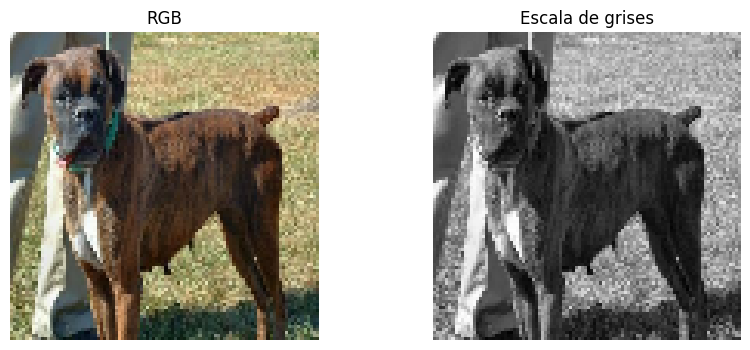

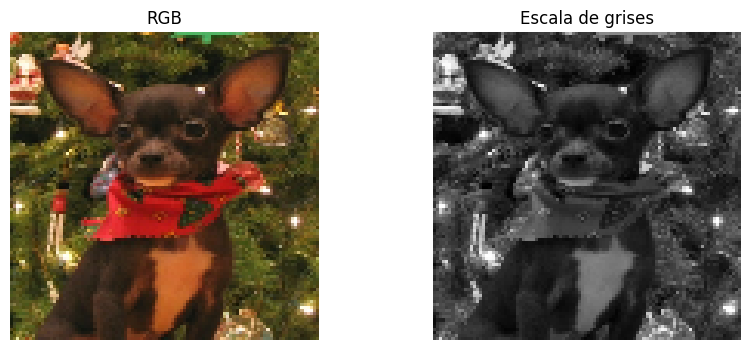

In [ ]:
for image, label in train_ds_norm.take(2):

    gray = tf.image.rgb_to_grayscale(image)

    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.imshow(image)
    plt.title("RGB")
    plt.axis('off')

    plt.subplot(1,2,2)
    plt.imshow(tf.squeeze(gray), cmap='gray')
    plt.title("Escala de grises")

    plt.axis('off')

    plt.show()

# Preguntas de análisis

1. ¿Qué podría ocurrir si no normalizamos?
2. ¿Por qué todas las imágenes deben tener el mismo tamaño?
3. ¿Qué ventajas y desventajas tiene usar escala de grises?
4. ¿Qué pierde la IA cuando reducimos información?

***
***
#**4. Neural Network model**

###Activation Functions
<p float="left">
  <img src="https://www.researchgate.net/profile/Rahul-Jayawardana/publication/350567223/figure/fig3/AS:1007855343767554@1617302847631/Fig-3-The-basic-activation-functions-of-the-neural-networksNeural-Networks.jpg" width="600"/>
</p>


###Dropout technique
<p float="left">
  <img src="https://miro.medium.com/max/640/1*dEi_IkVB7IpkzZ-6H0Vpsg.png" width="600"/>
</p>

# Primera aproximación: Red Neuronal Densa

Antes de usar CNN intentaremos resolver el problema con una red neuronal tradicional.

Estas redes funcionan muy bien para:

- datos tabulares
- números
- vectores

Pero presentan dificultades con imágenes.

# Problema

Las redes densas reciben vectores unidimensionales.

Sin embargo, una imagen tiene estructura tridimensional:

(alto, ancho, canales)

Por esta razón debemos convertir la imagen en un vector.

In [ ]:
for image, label in train_ds_norm.take(1):

    print("Forma original:")
    print(image.shape)

Forma original:
(100, 100, 3)


In [ ]:
flatten = tf.keras.layers.Flatten()

for image, label in train_ds_norm.take(1):

    flattened = flatten(tf.expand_dims(image, 0))

    print("\nForma después de Flatten:")
    print(flattened.shape)


Forma después de Flatten:
(1, 30000)


# ¿Qué hizo Flatten?

Flatten tomó la matriz de la imagen y la convirtió en un vector largo.

La imagen pierde su estructura espacial original.

# Reflexión

Después de aplicar Flatten:

- la red ya no sabe qué píxeles estaban cerca
- desaparecen filas y columnas
- solo queda una lista de números

La imagen pierde contexto espacial.

In [ ]:
modelo_denso = tf.keras.Sequential([

    tf.keras.layers.Flatten(input_shape=(100,100,3)),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


# Arquitectura

## Flatten
Convierte la imagen en un vector.

## Dense(128)
Aprende relaciones matemáticas entre valores.

## Dense(1)
Genera la clasificación final:

- 0 → gato
- 1 → perro

In [ ]:
modelo_denso.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,840,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,840,257 (14.65 MB)

 Trainable params: 3,840,257 (14.65 MB)

 Non-trainable params: 0 (0.00 B)

# Pregunta de análisis

¿De dónde salen todos estos parámetros y por qué este modelo tiene tantos parámetros?

¿Qué ocurrirá si aumentamos o disminuimos el tamaño de la imagen?

# Batch de imágenes

Las redes neuronales normalmente no entrenan una imagen a la vez.

Entrenan grupos de imágenes llamados batches.

Por eso TensorFlow espera una dimensión adicional:

(batch_size, alto, ancho, canales)

In [ ]:
BATCH_SIZE = 32

train_ds_batch = train_ds_norm.batch(BATCH_SIZE)

In [ ]:
for images, labels in train_ds_batch.take(1):

    print("Forma batch imágenes:")
    print(images.shape)

Forma batch imágenes:
(32, 100, 100, 3)


In [ ]:
tf.keras.backend.clear_session()

modelo_denso = tf.keras.Sequential([

    tf.keras.layers.Flatten(input_shape=(100,100,3)),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(1, activation='sigmoid')
])

modelo_denso.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = modelo_denso.fit(
    train_ds_batch,
    epochs=5
)

Epoch 1/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 27s 35ms/step - accuracy: 0.5011 - loss: 0.8376
Epoch 2/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 24s 33ms/step - accuracy: 0.5006 - loss: 0.6932
Epoch 3/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 24s 32ms/step - accuracy: 0.5008 - loss: 0.6932
Epoch 4/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 24s 32ms/step - accuracy: 0.5006 - loss: 0.6932
Epoch 5/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 41s 32ms/step - accuracy: 0.5005 - loss: 0.6932


# Análisis

Aunque la red logra aprender parcialmente:

- el entrenamiento es costoso
- hay demasiados parámetros
- se pierde información espacial

# Limitaciones de las Redes Densas en Imágenes

Las imágenes contienen patrones espaciales importantes:

- bordes
- formas
- texturas
- regiones

Las redes densas **no aprovechan** bien esta estructura.

**Por esta razón surgieron las Redes Neuronales Convolucionales (CNN).**

# Idea importante

Una imagen no es simplemente un conjunto de números.

También contiene organización espacial.

La estructura de los datos afecta directamente la arquitectura del modelo.

# ¿Por qué necesitamos CNN?

Las redes densas presentan varios problemas con imágenes:

- demasiados parámetros
- alto costo computacional
- pérdida de estructura espacial

Sin embargo, las imágenes contienen patrones importantes como:

- bordes
- texturas
- formas
- regiones

Las Redes Neuronales Convolucionales (CNN) fueron diseñadas específicamente para trabajar con imágenes.

# Idea central de una CNN

Una CNN analiza pequeñas regiones de la imagen a la vez.

En lugar de observar todos los píxeles simultáneamente, aprende patrones locales como:

- líneas
- bordes
- esquinas
- texturas

Es similar a cómo un humano observa partes de una imagen para reconocer objetos.

***
***

# **4.1: INTRO TO CNNs - BACKGROUND**

##Images classification using Neural Networks - Deep Learning

<p float="left">
  <img src="https://miro.medium.com/max/720/1*zUATaXMAmKof27rPyBRWsg.png" width="400"/>
</p>

***
Feature extraction:
<p float="left">

  <img src="https://www.researchgate.net/profile/Scott-Grigsby/publication/325530258/figure/fig2/AS:680182054666246@1539179447479/Structure-of-a-deep-neural-net-DNN-for-facial-recognition-6.png" width="900"/>
</p>

<p float="left">
  <img src="https://developer-blogs.nvidia.com/wp-content/uploads/2015/11/hierarchical_features.png" width="800"/>
</p>

***
Convolutional Kernels

<p float="left">
  <img src="https://www.researchgate.net/publication/354036236/figure/fig2/AS:1132444669493302@1647007257649/Operations-carried-out-by-the-convolution-and-pooling-layers-A-max-pooling-layer-picks.jpg" width="600"/>
</p>

<p float="left">
  <img src="https://miro.medium.com/max/1206/1*ZPXWZDIHFbTxs-6KVPS5gg.png" width="700"/>
</p>


# Convolución

Una convolución aplica un pequeño filtro sobre diferentes regiones de la imagen para detectar patrones.

In [ ]:
import numpy as np

kernel = np.array([
    [1,0,-1],
    [1,0,-1],
    [1,0,-1]
])

print(kernel)

[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]


Este filtro puede detectar bordes verticales.

# Filtros aprendidos

En Deep Learning los filtros no se programan manualmente.

La red neuronal aprende automáticamente qué patrones son importantes.

# Pooling

Después de detectar características, reducimos dimensionalidad para:

- disminuir costo computacional
- conservar información importante
- mejorar generalización

MaxPooling conserva los valores más importantes de una región.

In [ ]:
matriz = np.array([
    [1,2,1,0],
    [5,6,2,1],
    [3,1,7,2],
    [0,2,4,8]
])

print(matriz)

[[1 2 1 0]
 [5 6 2 1]
 [3 1 7 2]
 [0 2 4 8]]


El valor máximo de cada región se conserva.

In [ ]:
tf.keras.layers.Conv2D(
    32,
    (3,3),
    activation='relu',
    input_shape=(100,100,3)
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


<Conv2D name=conv2d, built=False>

# Interpretación

- 32 filtros
- tamaño 3x3
- extracción de características locales

In [ ]:
tf.keras.layers.MaxPooling2D(2,2)

<MaxPooling2D name=max_pooling2d, built=True>

Reducimos dimensionalidad manteniendo información importante.

In [ ]:
tf.keras.backend.clear_session()

modelo_cnn = tf.keras.Sequential([

    tf.keras.layers.Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(100,100,3)
    ),

    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(
        64,
        (3,3),
        activation='relu'
    ),

    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [ ]:
modelo_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,333,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353,217 (16.61 MB)

 Trainable params: 4,353,217 (16.61 MB)

 Non-trainable params: 0 (0.00 B)

# Comparación

Observe:

- cantidad de parámetros
- profundidad
- organización del modelo

¿Por qué esta arquitectura puede ser más eficiente para imágenes?

In [ ]:
modelo_cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history_cnn = modelo_cnn.fit(
    train_ds_batch,
    epochs=5
)

Epoch 1/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 31s 37ms/step - accuracy: 0.6695 - loss: 0.6036
Epoch 2/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.7779 - loss: 0.4701
Epoch 3/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.8304 - loss: 0.3788
Epoch 4/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.8813 - loss: 0.2829
Epoch 5/5
727/727 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.9231 - loss: 0.1914


# Comparación de modelos

## Red densa
- pierde estructura espacial
- muchos parámetros
- menor eficiencia

## CNN
- preserva patrones espaciales
- aprende características locales
- mejor adaptada para imágenes

# Comparación de Arquitecturas

Construiremos tres modelos diferentes para analizar cómo cambia el desempeño al modificar la arquitectura.

## Modelos

1. Red neuronal densa
2. CNN básica
3. CNN con regularización Dropout

El objetivo no es solo entrenar modelos, sino comparar:

- capacidad de aprendizaje
- generalización
- complejidad
- riesgo de overfitting

# Función de Activación Sigmoid

Utilizaremos la función de activación sigmoid en la capa de salida.

La función sigmoid transforma cualquier valor en un número entre:  0 y 1

Interpretación:

- valores cercanos a 0 → gato
- valores cercanos a 1 → perro

Como tenemos únicamente dos clases, este problema es de clasificación binaria.

# Pregunta

¿Por qué no necesitamos dos neuronas de salida para este problema?

# Modelo 1 — Red Neuronal Densa

Este modelo convierte la imagen en un vector usando Flatten.

Posteriormente aplica capas densas tradicionales.

Hipótesis:

- aprenderá parcialmente
- tendrá muchos parámetros
- no aprovechará bien la estructura espacial

# Modelo 2 — CNN Básica

Ahora utilizaremos una arquitectura convolucional.

La CNN intentará aprender automáticamente:

- bordes
- texturas
- formas
- patrones visuales

preservando la estructura espacial de la imagen.

# Overfitting

Una red neuronal puede memorizar el conjunto de entrenamiento en lugar de aprender patrones generales.

Esto se conoce como overfitting.

# Dropout

Dropout desactiva aleatoriamente algunas neuronas durante el entrenamiento.

Esto obliga a la red a aprender representaciones más robustas y reduce overfitting.

Durante el entrenamiento algunas conexiones se ignoran temporalmente.

###4.1 CREATING THE MODELS AND THE NEURAL NETWORKS

In [ ]:
#Crear los modelos iniciales
#Usan sigmoid como salida (en lugar de softmax) para mostrar como podria funcionar con dicha funcion de activacion.
#Sigmoid regresa siempre datos entre 0 y 1. Realizamos el entrenamiento para al final considerar que si la respuesta se
#acerca a 0, es un gato, y si se acerca a 1, es un perro.

IMAGE_SZ=100

modeloDenso = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN = tf.keras.models.Sequential([
  # Extracción inicial de características
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
   # Reducción dimensional
  tf.keras.layers.MaxPooling2D(2, 2),
   # Extracción de patrones más complejos
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
   # Características de mayor nivel
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  # Conversión a vector
  tf.keras.layers.Flatten(),
   # Clasificación
  tf.keras.layers.Dense(IMAGE_SZ, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN2 = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  # Regularización
  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(IMAGE_SZ, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

In [ ]:
modeloDenso.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 150)            │     1,500,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 150)            │        22,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           151 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,522,951 (5.81 MB)

 Trainable params: 1,522,951 (5.81 MB)

 Non-trainable params: 0 (0.00 B)

# Análisis

Observe la cantidad de parámetros entrenables.

¿Por qué una red densa puede crecer rápidamente en complejidad al trabajar con imágenes?

In [ ]:
modeloCNN.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 98, 98, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │     1,280,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,372,873 (5.24 MB)

 Trainable params: 1,372,873 (5.24 MB)

 Non-trainable params: 0 (0.00 B)

# Comparación

Compare este modelo con la red densa:

- ¿Qué diferencias observa?
- ¿Qué capas nuevas aparecen?
- ¿Por qué existen varias convoluciones?

In [ ]:
modeloCNN2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 98, 98, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │     1,280,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,372,873 (5.24 MB)

 Trainable params: 1,372,873 (5.24 MB)

 Non-trainable params: 0 (0.00 B)

###4.2 COMPILING THE NEURAL NETWORK MODELS

In [ ]:

IMG_SIZE = 100

# Preprocesamiento optimizado
def preprocess(image, label):
    image = tf.image.rgb_to_grayscale(image)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Aplicar transformaciones
train_ds_processed = (
    train_ds_norm
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()
    .prefetch(tf.data.AUTOTUNE)
)

# Convertir dataset a arreglos numpy
X = np.concatenate([
    image.numpy()[np.newaxis, ...]
    for image, label in train_ds_processed
])

y = np.array([
    label.numpy()
    for image, label in train_ds_processed
])

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (23262, 100, 100, 1)
Shape y: (23262,)


In [ ]:
#Compilar modelos. Usar crossentropy binario ya que tenemos solo 2 opciones (perro o gato)
modeloDenso.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN2.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

###4.2 CREATING A TENSORBOARD TO CATCH METRICS AND ENABLE THE LOSS CURVES

# ¿Por qué monitorear el entrenamiento?

Durante el entrenamiento necesitamos observar:

- accuracy
- loss
- overfitting
- comportamiento del modelo

TensorBoard nos permite visualizar estas métricas.

In [ ]:
#pip install tensorboard???

from tensorflow.keras.callbacks import TensorBoard
#La variable de tensorboard se envia en el arreglo de "callbacks" (hay otros tipos de callbacks soportados)
#En este caso guarda datos en la carpeta indicada en cada epoca, de manera que despues
#Tensorboard los lee para hacer graficas
tensorboardDenso = TensorBoard(log_dir='logs/denso')

###4.3 TRAINING THE FIRST MODEL

In [ ]:
modeloDenso.fit(X, y, batch_size=32,
                validation_split=0.15,
                epochs=10,
                callbacks=[tensorboardDenso])

Epoch 1/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.5382 - loss: 0.6869 - val_accuracy: 0.5828 - val_loss: 0.6742
Epoch 2/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5828 - loss: 0.6747 - val_accuracy: 0.5676 - val_loss: 0.6814
Epoch 3/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5963 - loss: 0.6661 - val_accuracy: 0.5989 - val_loss: 0.6636
Epoch 4/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6070 - loss: 0.6584 - val_accuracy: 0.6037 - val_loss: 0.6593
Epoch 5/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6143 - loss: 0.6527 - val_accuracy: 0.6011 - val_loss: 0.6591
Epoch 6/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6226 - loss: 0.6478 - val_accuracy: 0.6083 - val_loss: 0.6537
Epoch 7/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6288 - loss: 0.6432 - val_accuracy: 0.6155 - val_loss: 0.6481
Epoch 8/10
618/618 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6305 - loss: 0.6396 - val_accuracy: 0.

In [ ]:
#Cargar la extension de tensorboard de colab
%load_ext tensorboard
#Ejecutar tensorboard e indicarle que lea la carpeta "logs"
%tensorboard --logdir logs

<IPython.core.display.Javascript object>

In [ ]:
tensorboardCNN = TensorBoard(log_dir='logs/cnn')
modeloCNN.fit(X, y, batch_size=128,
                validation_split=0.15,
                epochs=20,
                callbacks=[tensorboardCNN])

Epoch 1/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.5013 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6933
Epoch 2/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - accuracy: 0.5029 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6933
Epoch 3/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.5029 - loss: 0.6931 - val_accuracy: 0.4914 - val_loss: 0.6932
Epoch 4/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.5029 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6932
Epoch 5/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.5029 - loss: 0.6931 - val_accuracy: 0.4914 - val_loss: 0.6933
Epoch 6/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.5029 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6933
Epoch 7/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.5029 - loss: 0.6931 - val_accuracy: 0.4914 - val_loss: 0.6933
Epoch 8/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.5029 - loss: 0.6932 - val_acc

In [ ]:
tensorboardCNN2 = TensorBoard(log_dir='logs/cnn2')
modeloCNN2.fit(X, y, batch_size=128,
                validation_split=0.15,
                epochs=20,
                callbacks=[tensorboardCNN2])

Epoch 1/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step - accuracy: 0.4983 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6932
Epoch 2/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.5029 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6932
Epoch 3/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.5029 - loss: 0.6931 - val_accuracy: 0.4914 - val_loss: 0.6932
Epoch 4/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.5017 - loss: 0.6932 - val_accuracy: 0.4914 - val_loss: 0.6932
Epoch 5/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.5029 - loss: 0.6931 - val_accuracy: 0.4914 - val_loss: 0.6933
Epoch 6/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.5029 - loss: 0.6931 - val_accuracy: 0.4914 - val_loss: 0.6933
Epoch 7/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.5029 - loss: 0.6931 - val_accuracy: 0.4914 - val_loss: 0.6933
Epoch 8/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.5029 - loss: 0.6931 - val_acc

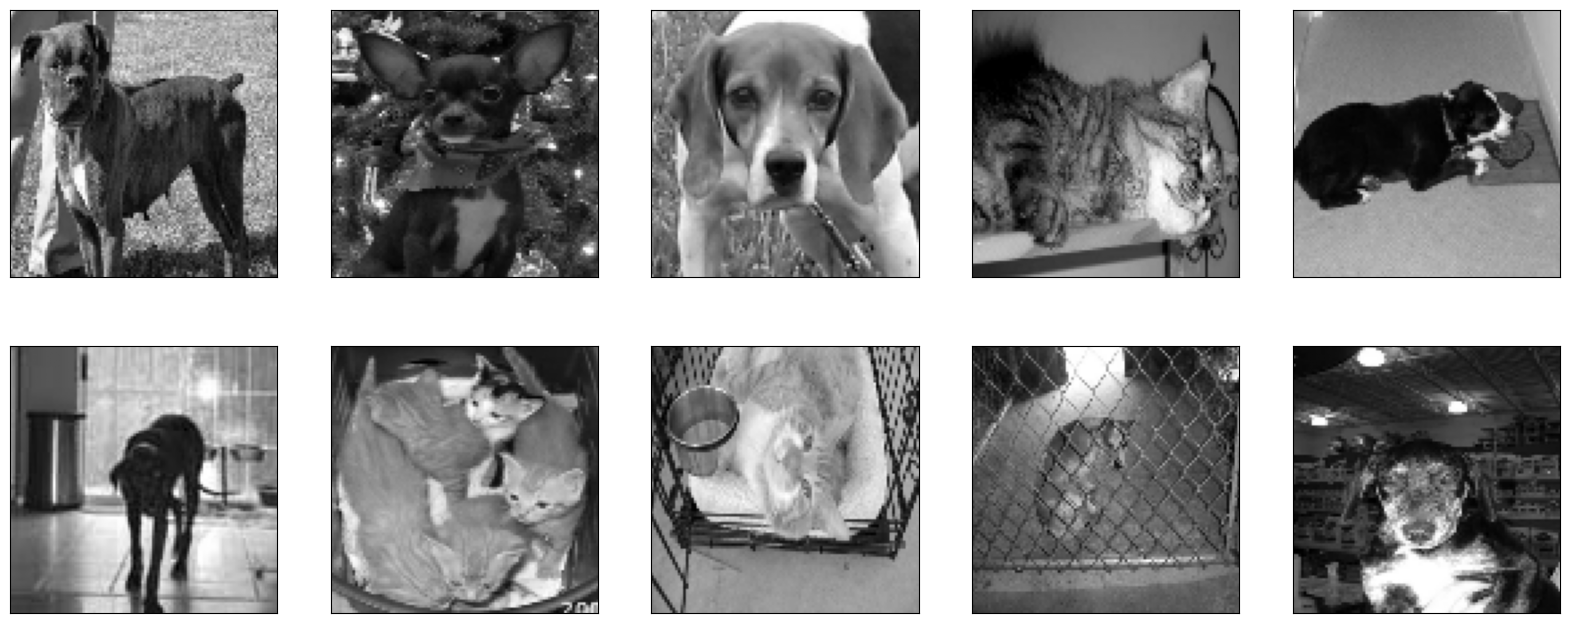

In [ ]:
#ver las imagenes de la variable X sin modificaciones por aumento de datos
plt.figure(figsize=(20, 8))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(X[i].reshape(IMAGE_SZ, IMAGE_SZ), cmap="gray")

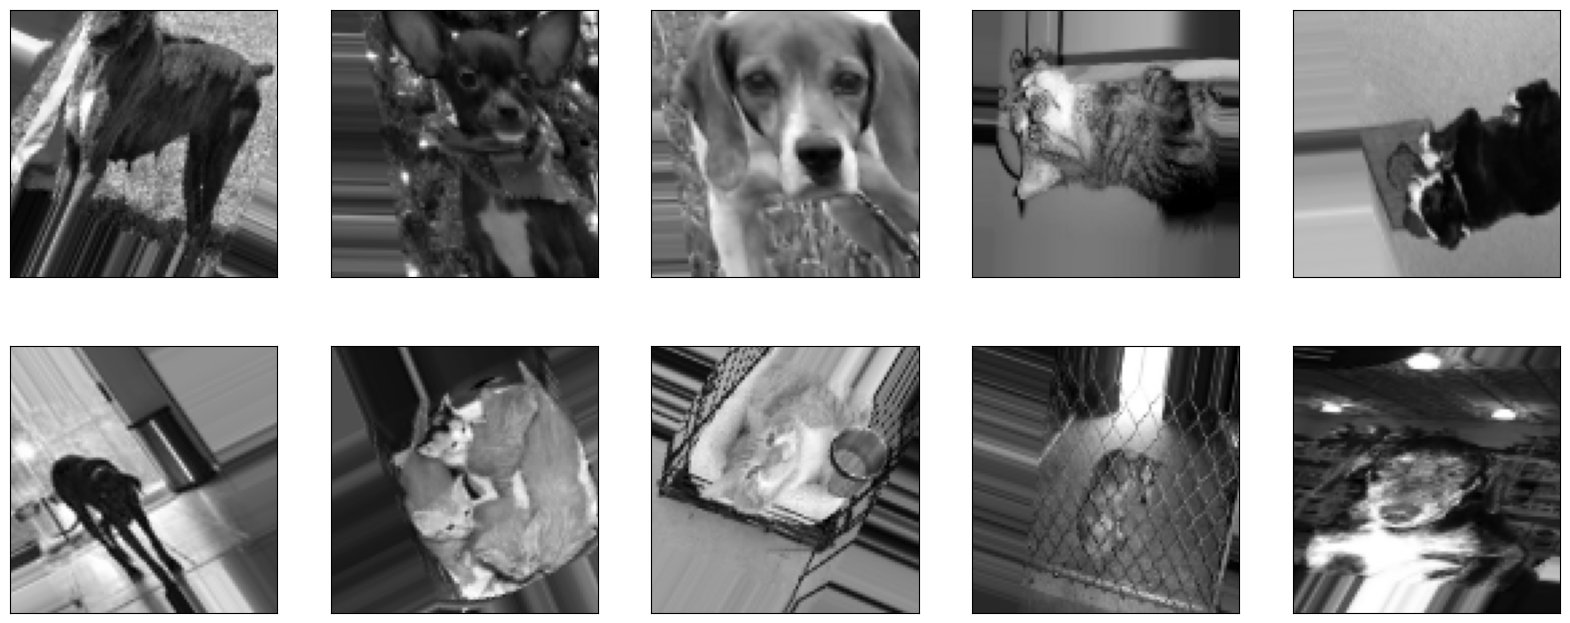

In [ ]:
#Realizar el aumento de datos con varias transformaciones. Al final, graficar 10 como ejemplo
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=15,
    zoom_range=[0.7, 1.4],
    horizontal_flip=True,
    vertical_flip=True
)

datagen.fit(X)

plt.figure(figsize=(20,8))

for imagen, etiqueta in datagen.flow(X, y, batch_size=10, shuffle=False):
  for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(imagen[i].reshape(IMAGE_SZ, IMAGE_SZ), cmap="gray")
  break

In [ ]:
modeloDenso_AD = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN_AD = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(100, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN2_AD = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMAGE_SZ, IMAGE_SZ, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(250, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
modeloDenso_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

modeloCNN2_AD.compile(optimizer='adam',
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

In [ ]:
#Separar los datos de entrenamiento y los datos de pruebas en variables diferentes

len(X) * .85 #19700
len(X) - 19700 #3562

X_entrenamiento = X[:19700]
X_validacion = X[19700:]

y_entrenamiento = y[:19700]
y_validacion = y[19700:]

In [ ]:
#Usar la funcion flow del generador para crear un iterador que podamos enviar como entrenamiento a la funcion FIT del modelo
data_gen_entrenamiento = datagen.flow(X_entrenamiento, y_entrenamiento, batch_size=32)
tensorboardDenso_AD = TensorBoard(log_dir='logs/denso_AD')

modeloDenso_AD.fit(
    data_gen_entrenamiento,
    epochs=50, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardDenso_AD]
)
tensorboardCNN_AD = TensorBoard(log_dir='logs-new/cnn_AD')

modeloCNN_AD.fit(
    data_gen_entrenamiento,
    epochs=50, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardCNN_AD]
)
tensorboardCNN2_AD = TensorBoard(log_dir='logs/cnn2_AD')

modeloCNN2_AD.fit(
    data_gen_entrenamiento,
    epochs=50, batch_size=32,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardCNN2_AD]
)

In [ ]:
modeloCNN_AD.save('perros-gatos-cnn-ad.h5')
!pip install tensorflowjs
!mkdir carpeta_salida
!tensorflowjs_converter --input_format keras perros-gatos-cnn-ad.h5 carpeta_salida

***
***
##Transfer learning

<p float="left">

  <img src="https://www.freetimelearning.com/images/interview_questions/transfer_learning.jpg" width="800"/>

</p>


<p float="left">

  <img src="https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/misc-tensorflow-workflow-outline.png" width="800"/>

</p>
<p float="left">

  <img src="https://pbs.twimg.com/media/ES2EanFXQAIW78Y?format=jpg&name=medium" width="800"/>

</p>

# Conclusiones

En este laboratorio aprendimos:

- cómo funciona un pipeline de visión artificial
- diferencias entre redes densas y CNN
- importancia del preprocesamiento
- impacto del aumento de datos
- interpretación básica de métricas